# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids_file = "unit2_ppt5_country_centroids_computed.csv"
centroids = pd.read_csv(centroids_file)
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [2]:
# TODO 1: choropleth of total_gdp
fig_total = px.choropleth(
    gap_latest, locations="iso_alpha", color="total_gdp",
    hover_name="country", hover_data=["pop", "gdpPercap", "total_gdp"],
    color_continuous_scale="Blues", title="Total GDP by Country (2007)"
)
fig_total.show()

# TODO 2: choropleth of gdpPercap
fig_rate = px.choropleth(
    gap_latest, locations="iso_alpha", color="gdpPercap",
    hover_name="country", hover_data=["pop", "gdpPercap", "total_gdp"],
    color_continuous_scale="Viridis", title="GDP per Capita by Country (2007)"
)
fig_rate.show()

# TODO 3: top 5 countries by each -- print both lists
top_total = gap_latest.nlargest(5, "total_gdp")[["country", "total_gdp"]]
top_rate = gap_latest.nlargest(5, "gdpPercap")[["country", "gdpPercap"]]
print("Top 5 by total GDP:\n", top_total)
print("\nTop 5 by GDP per capita:\n", top_rate)


Top 5 by total GDP:
            country     total_gdp
134  United States  1.293446e+13
24           China  6.539501e+12
66           Japan  4.035135e+12
58           India  2.722925e+12
47         Germany  2.650871e+12

Top 5 by GDP per capita:
            country    gdpPercap
95          Norway  49357.19017
71          Kuwait  47306.98978
113      Singapore  47143.17964
134  United States  42951.65309
62         Ireland  40675.99635


**Reflection:** The top-total-GDP list is dominated by large economies, while the GDP-per-capita list highlights countries with high output relative to population and can include smaller wealthy countries. I would show the GDP-per-capita map when comparing development or average economic prosperity because it is normalized per person and less dominated by country size. Total GDP is still useful when the question is about the overall size of an economy.

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

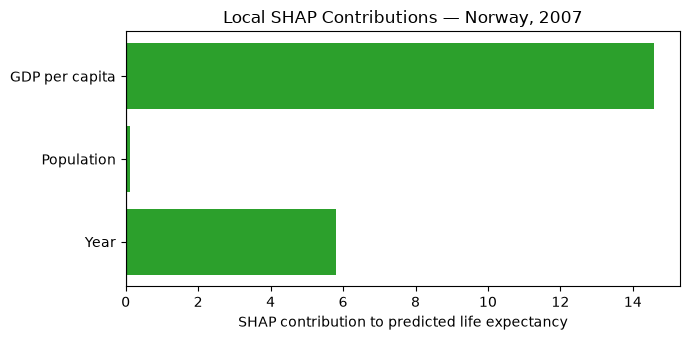

In [3]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values

# TODO 1: fit the model
rf = RandomForestRegressor(n_estimators=200, random_state=0)
rf.fit(X_model, y_model)

# TODO 2: SHAP explainer + values
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_model)

# TODO 3: find Norway's row, plot its SHAP contributions
row_idx = gapminder.index[(gapminder.country == "Norway") & (gapminder.year == 2007)][0]
vals = np.asarray(shap_values)[row_idx]
feature_names = ["GDP per capita", "Population", "Year"]

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in vals]
ax.barh(feature_names, vals, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP contribution to predicted life expectancy")
ax.set_title("Local SHAP Contributions — Norway, 2007")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Reflection:** GDP per capita is expected to be the strongest positive contributor to Norway's predicted life expectancy, while population may contribute negatively or have a smaller effect depending on the fitted model. A global feature-importance chart cannot show the direction and magnitude of contributions for one specific country. SHAP's local explanation shows how each feature pushes this individual prediction up or down.

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

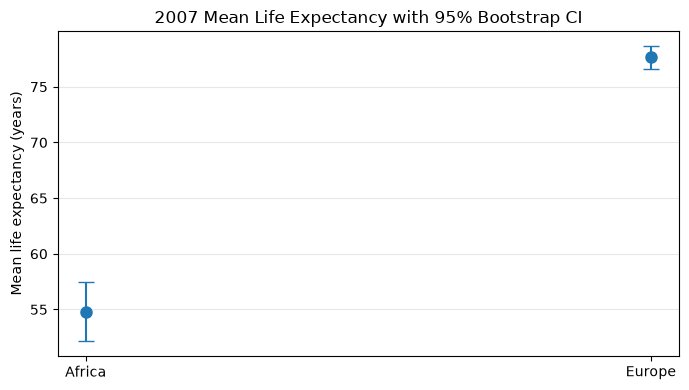

Africa: mean=54.81, 95% CI=(52.15, 57.44)
Europe: mean=77.65, 95% CI=(76.57, 78.65)


In [4]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boot_means = np.empty(n_boot)
    # Resample values with replacement and calculate each sample mean
    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        boot_means[i] = sample.mean()
    mean = values.mean()
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    return mean, ci_low, ci_high

# TODO 2: compute CIs for two continents of your choice
continent_a, continent_b = "Africa", "Europe"
values_a = gap_latest[gap_latest.continent == continent_a].lifeExp.values
values_b = gap_latest[gap_latest.continent == continent_b].lifeExp.values
result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)

# TODO 3: plot both as error bars (mean +/- CI half-width)
means = [result_a[0], result_b[0]]
lower_errors = [result_a[0] - result_a[1], result_b[0] - result_b[1]]
upper_errors = [result_a[2] - result_a[0], result_b[2] - result_b[0]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar([continent_a, continent_b], means, yerr=[lower_errors, upper_errors],
            fmt="o", capsize=6, markersize=8)
ax.set_ylabel("Mean life expectancy (years)")
ax.set_title("2007 Mean Life Expectancy with 95% Bootstrap CI")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"{continent_a}: mean={result_a[0]:.2f}, 95% CI=({result_a[1]:.2f}, {result_a[2]:.2f})")
print(f"{continent_b}: mean={result_b[0]:.2f}, 95% CI=({result_b[1]:.2f}, {result_b[2]:.2f})")


**Reflection:** The wider interval is affected by both variation among countries (standard deviation) and the number of countries (sample size). Higher variation widens the interval, while a larger sample generally narrows it. Comparing the two intervals helps illustrate that confidence-interval width is not determined by variation alone.

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

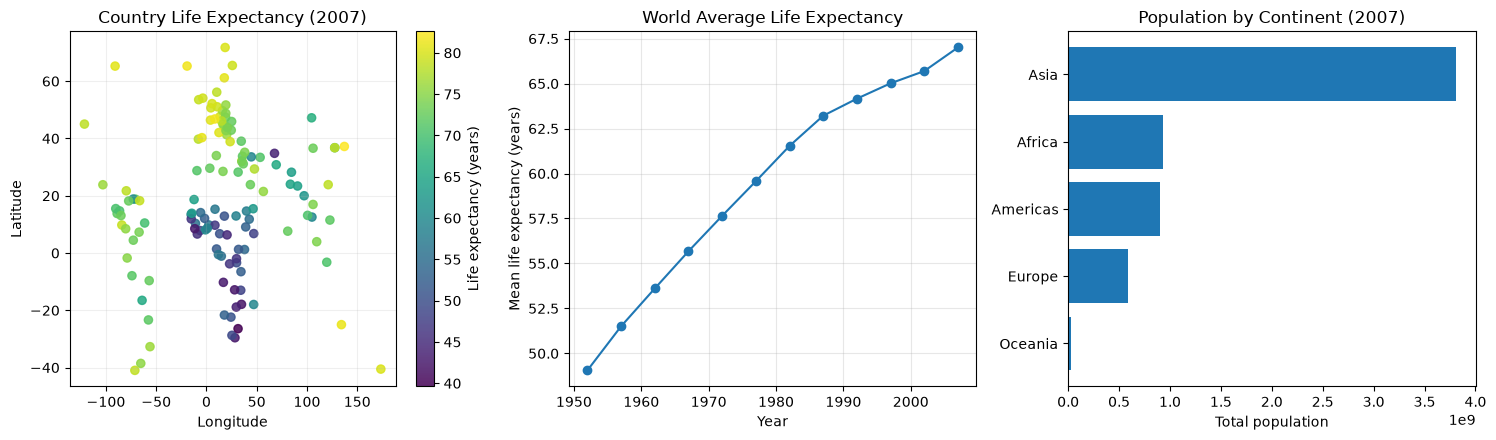

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# TODO 1: map-style scatter (axes[0])
sc = axes[0].scatter(gap_latest["centroid_lon"], gap_latest["centroid_lat"],
                    c=gap_latest["lifeExp"], cmap="viridis", s=35, alpha=0.85)
axes[0].set_title("Country Life Expectancy (2007)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].grid(alpha=0.2)
fig.colorbar(sc, ax=axes[0], label="Life expectancy (years)")

# TODO 2: world trend line (axes[1])
world_trend = gapminder.groupby("year", as_index=False)["lifeExp"].mean()
axes[1].plot(world_trend["year"], world_trend["lifeExp"], marker="o")
axes[1].set_title("World Average Life Expectancy")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Mean life expectancy (years)")
axes[1].grid(alpha=0.3)

# TODO 3: population by continent bar chart (axes[2])
continent_pop = gap_latest.groupby("continent")["pop"].sum().sort_values()
axes[2].barh(continent_pop.index, continent_pop.values)
axes[2].set_title("Population by Continent (2007)")
axes[2].set_xlabel("Total population")

plt.tight_layout()
plt.show()


**Reflection:** I would keep the world-average life-expectancy trend line because it quickly shows whether global development is improving, stagnating, or changing over time. It answers the monitoring question: “Is the overall trend moving in the expected direction, and are there periods where it changes?” The map is better for geographic differences, while the bar chart is better for comparing continent population sizes.

**Final recommendation:** I would standardize on rate-based maps such as GDP per capita when comparing development across countries, because raw total GDP is strongly affected by population and country size; total GDP is useful when the question concerns economic scale. When a journalist asks why the model predicted a value for a specific country, I would use local SHAP explanations rather than global feature importance, because local explanations show the signed contribution of each feature to that individual prediction. Global importance describes the model overall but does not explain a particular case. The dashboard should show uncertainty for estimates such as mean life expectancy instead of presenting a single number without a confidence interval. I would retain geographic context, a trend view, and a comparison view so the dashboard supports quick monitoring without misleading the audience.